# Логистическая регрессия и метод ближайших соседей


**Цель работы:** получение практических навыков использования модели логистической регрессии и метода ближайших соседей.

Продолжительность работы: - 4 часа.

Мягкий дедлайн (100 баллов): 27.11.2026

Жесткий дедлайн (50 баллов): 04.12.2026


## Логистическая регрессия

Метод логистической регрессии является мощным инструментом для бинарной классификации, обеспечивая простоту в интерпретации и применении. Однако для достижения лучшей производительности требуется тщательный выбор признаков и проверка предположений модели.

- Логистическая регрессия — это статистический метод, используемый для бинарной классификации. Он предсказывает вероятность принадлежности объекта к определенному классу на основе входных признаков.
- Логистическая регрессия использует логистическую функцию (сигмоиду), чтобы преобразовать линейную комбинацию входных признаков в вероятность.
  - Модель логистической регрессии:
$$
\hat y = \sigma (Xw).
$$
  - Сигмоида меняется в пределах от 0 до 1 и имеет вид:
$$
\sigma(x) = \frac{1}{1+e^{-x}}.
$$
-- Функция потерь log-loss:
$$
L = -\frac{1}{\ell}\sum_{i = 1}^{\ell}(y_i\log(\hat y_i) + (1 - y_i)\log(1 - \hat y_i)),
$$
где $\ell$ - количество объектов.
-- Регуляризация вводится таким же образом, как это было в случае линейной регрессии. Например, функция потерь для $L$-$2$ регуляризации выглядит так:
$$
\bar{L}(X, w) = L(X, w) + \frac{1}{2}\lambda\|w\|^2_2.
$$
- Коэффициенты модели алгоритм находит с помощью метода максимального правдоподобия, который максимизирует вероятность наблюдаемых данных, исходя из модели.
- Классификация производится путем установки порога (например, 0.5) для вероятностей. Если предсказанная вероятность превышает порог, объект классифицируется в один класс, иначе — в другой.
- Логистическая регрессия используется в различных областях, например:
  - Медицина (для диагностики болезней);
  - Финансовые услуги (для оценки кредитного риска);
  - Маркетинг (для прогноза успеха рекламных кампаний).
- Преимущества:
  - Простота и интерпретируемость модели.
  - Быстрая и эффективная при малом количестве признаков.
  - Легко адаптируется для многоклассовой классификации с помощью методов, таких как "один против всех".
- Недостатки:
  - Предположение о линейности отношений в логарифмической шкале.
  - Неэффективна при наличии сложных нелинейных зависимостей без дополнительной обработки (например, полиномиальные признаки).
  - Чувствительность к мультиколлинеарности (высокой корреляции между независимыми переменными).
  
## Метод ближайших соседей

Метод ближайших соседей (k-NN) является мощным инструментом для классификации и регрессии, однако его эффективность и точность зависят от правильного выбора параметров и методов обработки данных. Для многих задач может потребоваться предварительная обработка данных и оптимизация для достижения наилучших результатов.

- Для классификации нового объекта алгоритм k-NN ищет k ближайших к нему соседей в обучающей выборке, основываясь на заданной метрике расстояния.
- Класс нового объекта определяется по большинству голосов его ближайших соседей (например, класс, который чаще всего встречается среди соседей).
- Наиболее распространенными метриками расстояний являются:
  - Евклидово расстояние: 
  $d(p, q) = \sqrt{\sum_{i=1}^{n}(p_i - q_i)^2}$    
  - Манхэттенское расстояние: 
$$d(p, q) = \sum_{i=1}^{n}|p_i - q_i|$$
  - Расстояние Минковского: 
$$d(p, q) = \left(\sum_{i=1}^{n}|p_i - q_i|^r\right)^{1/r}$$
где $r$ — параметр, определяющий тип расстояния).
- Параметр k (количество соседей) является критически важным для работы алгоритма:
  - Небольшие значения k могут приводить к переобучению (алгоритм очень чувствителен к шуму).
  - Большие значения k могут приводить к недообучению (общее усреднение данных).
- Новый объект классифицируется на основе классов его ближайших соседей. Каждому соседу присваивается вес по частоте его класса, и выбирается класс с наибольшим голосом.
- Взвешенные методы могут использоваться для улучшения точности классификации, где соседи, находящиеся ближе, могут иметь больший вес.
- Метод k-NN демонстрирует снижение эффективности с увеличением числа измерений, что называется "проклятием размерности". Это связано с тем, что расстояния между точками становятся менее различимыми в высоких дименсиях.
- Метод k-NN широко используется в:
  - Распознавании образов (например, в задачах компьютерного зрения);
  - Рекомендательных системах;
  - Медицинской диагностике;
  - Классификации текстов и многом другом.
- Преимущества:
  - Простота реализации и понимания.
  - Нет необходимости в обучении (алгоритм использует все доступные данные).
  - Гибкость в использовании разных метрик расстояний.
- Недостатки:
  - Высокая вычислительная сложность (особенно на больших объемах данных).
  - Чувствительность к выбору k и метрикам расстояния.
  - Проблема проклятия размерности.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

## Практика

Рассмотрим свойства логистической регрессии и метода опорных векторов на примере классического набора данных ["Ирисы Фишера"](https://ru.wikipedia.org/wiki/Ирисы_Фишера). Этот набор состоит из 150 наблюдений, каждое из которых представляет собой четыре измерения: длина наружной доли околоцветника (`sepal length`), ширина наружной доли околоцветника (`sepal width`), длина внутренней доли околоцветника (`petal length`), ширина внутренней доли околоцветника (`petal width`). Каждое наблюдение относится к одному из трёх классов ириса: `setosa`, `versicolor` или `virginica`. Задача состоит в том, чтобы по измерениям предсказать класс цветка.

<img src="./img/iris.png" alt="drawing" width="800"/>

In [2]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)

data = iris['data']
y = iris['target'].values

In [3]:
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [4]:
y[:5]

array([0, 0, 0, 0, 0])

### Задание 1.

Перейдём к задаче бинарной классификации: будем предсказывать принадлежность цветка к виду `versicolor` против принадлежности ко всем прочим видам. Перекодируйте зависимую переменную так, чтобы цветки вида `versicolor` (y=1) имели метку 1, а прочих видов – метку 0.

In [5]:
# 1 — versicolor, 0 — остальные виды
y = (y == 1).astype(int)
print('Количество объектов каждого класса:', np.bincount(y))

Количество объектов каждого класса: [100  50]


### Задание 2.

Будем работать с двумя признаками: `sepal length (cm)` и `sepal width (cm)`. Построим диаграмму рассеяния по тренировочной выборке и убедитесь, что данные линейно не разделимы.

In [6]:
# Два выбранных признака
X = data[['sepal length (cm)', 'sepal width (cm)']].values
print('Размерность данных:', X.shape)

Размерность данных: (150, 2)


In [7]:
# делим данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)

Приведем значения всех входных признаков к одному масштабу. Для этого применим функцию `StandardScaler`. Это преобразование приводит значения каждого признака к нулевому среднему и единичной дисперсии:

$$
X_{new} = \frac{X - \mu}{\sigma}
$$

где, $\mu$ - среднее значение признака

$\sigma$ - стандартное отклонение значений признака

In [8]:
from sklearn.preprocessing import StandardScaler

ss = StandardScaler()
ss.fit(X_train, y_train) # считаем \mu и \sigma

# делаем преобразование данных
X_train_ss = ss.transform(X_train)
X_test_ss = ss.transform(X_test)

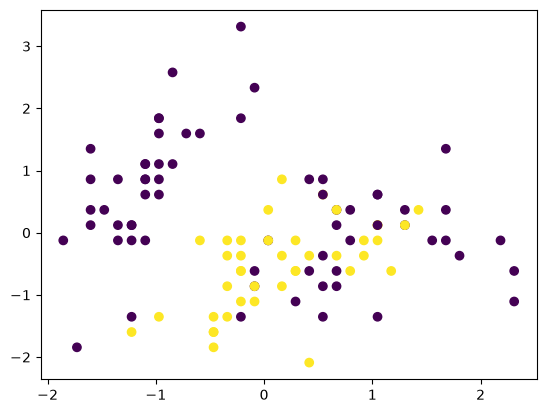

In [9]:
plt.scatter(X_train_ss[:, 0], X_train_ss[:, 1], c=y_train)
plt.show()

### Задание 3.

Сравним качество для KNN и логрега.

In [10]:
knn = KNeighborsClassifier(n_neighbors=5)
logreg = LogisticRegression()

#### Обучение

In [11]:
# Обучаем классификаторы на стандартизированных признаках
knn.fit(X_train_ss, y_train)
logreg.fit(X_train_ss, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

#### Прогноз метки класса

In [12]:
# Предсказанные метки классов
y_test_pred_knn = knn.predict(X_test_ss)
y_test_pred_logreg = logreg.predict(X_test_ss)

In [13]:
y_test_pred_knn[:5]

array([0, 1, 0, 1, 0])

In [14]:
y_test_pred_logreg[:5]

array([1, 0, 1, 0, 0])

#### Прогноз вероятности класса

In [15]:
# Вероятности принадлежности к классам 0 и 1
y_test_proba_knn = knn.predict_proba(X_test_ss)
y_test_proba_logreg = logreg.predict_proba(X_test_ss)

In [16]:
y_test_proba_knn[:5]

array([[1. , 0. ],
       [0.2, 0.8],
       [0.6, 0.4],
       [0. , 1. ],
       [1. , 0. ]])

In [17]:
y_test_proba_logreg[:5]

array([[0.29417961, 0.70582039],
       [0.57205493, 0.42794507],
       [0.46752787, 0.53247213],
       [0.63769064, 0.36230936],
       [0.90567108, 0.09432892]])

#### Метрика качества

In [18]:
from sklearn.metrics import accuracy_score
print(f'KNN: {accuracy_score(y_test, y_test_pred_knn)}')
print(f'LogReg: {accuracy_score(y_test, y_test_pred_logreg)}')

KNN: 0.7555555555555555
LogReg: 0.8444444444444444


#### Строим разделяющую поверность

Text(0.5, 1.0, 'Разделяющая поверхность для KNN')

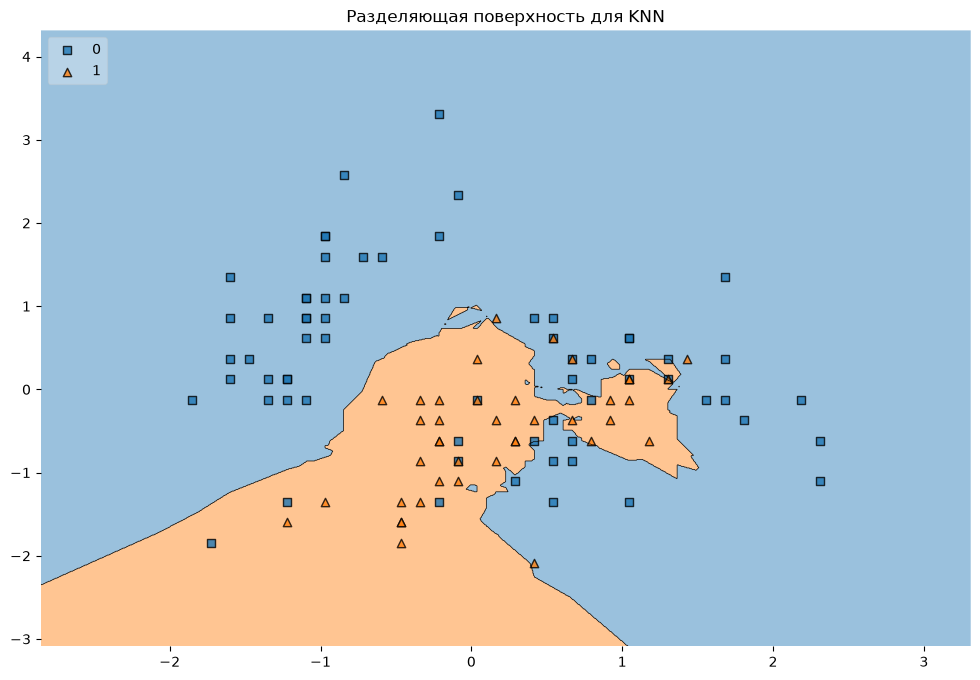

In [19]:
plt.figure(figsize=(12,8))
plot_decision_regions(X_train_ss, y_train, clf=knn, legend=2)
plt.title('Разделяющая поверхность для KNN')

Text(0.5, 1.0, 'Разделяющая поверхность для логрега')

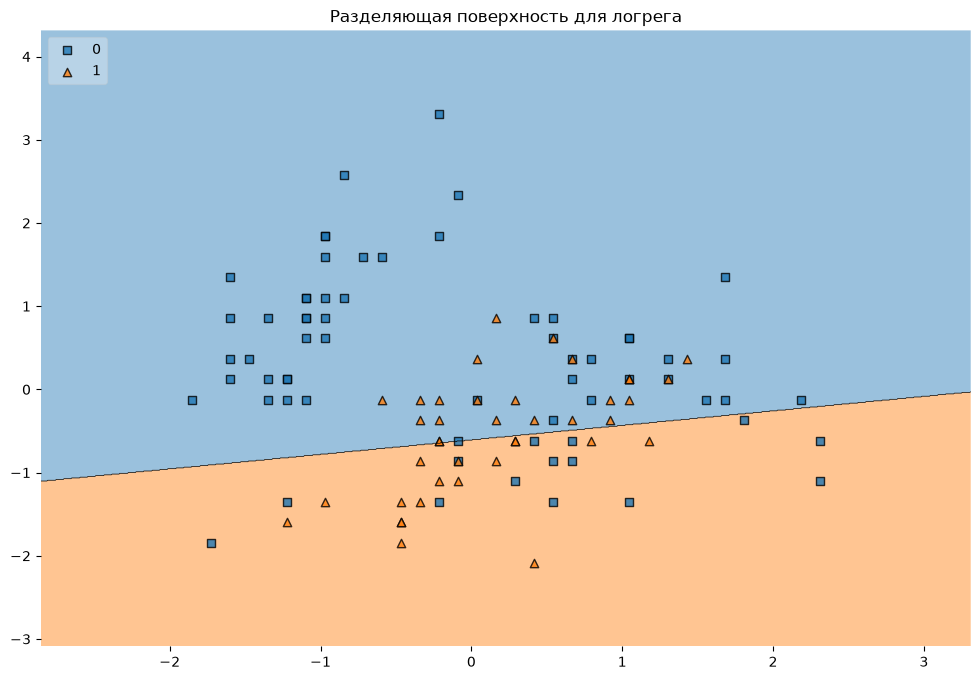

In [20]:
plt.figure(figsize=(12,8))
plot_decision_regions(X_train_ss, y_train, clf=logreg, legend=2)
plt.title('Разделяющая поверхность для логрега')

Теперь изучим свойства каждого классификатора по-отдельности. Начнём с логистической регрессии.
### Задание 4.

Обучите три различные логистические регрессии с разным параметром регуляризации $C$.

In [21]:
# Здесь должен быть ваш код

logreg_1 = LogisticRegression(C=0.01, max_iter=1000)
logreg_2 = LogisticRegression(C=0.05, max_iter=1000)
logreg_3 = LogisticRegression(C=10, max_iter=1000)

Правильность при C=0.01:  0.7777777777777778
Правильность при C=0.05:  0.8444444444444444
Правильность при C=10:  0.8444444444444444


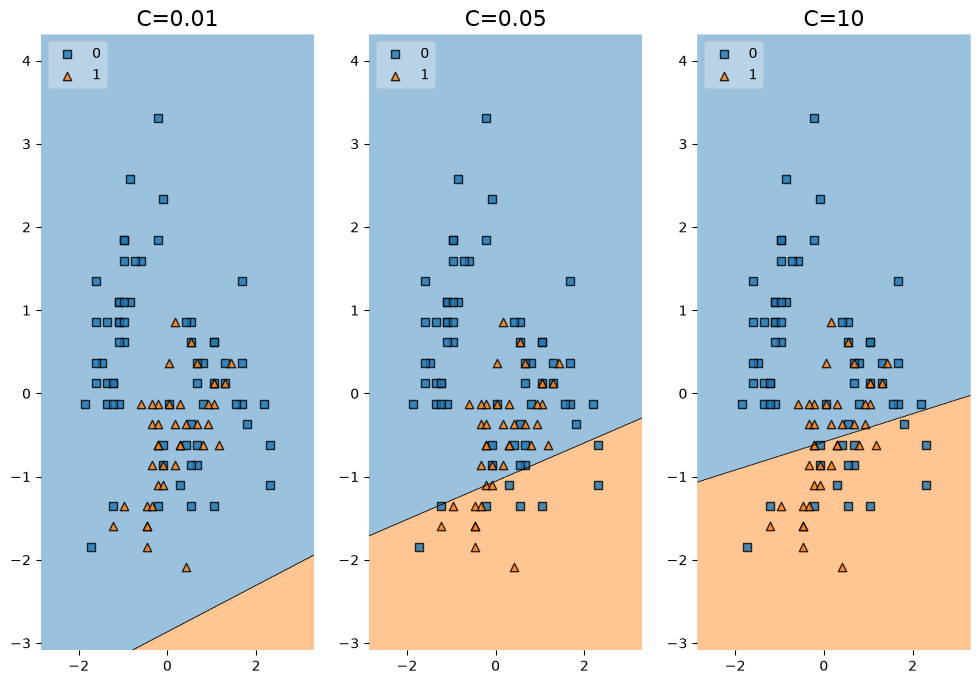

In [22]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 8))
pipes = [logreg_1, logreg_2, logreg_3]

for ind, clf in enumerate(pipes):
    clf.fit(X_train_ss, y_train)
    y_test_pred = clf.predict(X_test_ss)
    score = accuracy_score(y_test, y_test_pred)
    print(f"Правильность при C={clf.get_params()['C']}: ", score)
    fig = plot_decision_regions(X_train_ss, y_train, clf=clf, legend=2, ax=axes[ind])
    fig.set_title(f"C={clf.get_params()['C']}", fontsize=16)

Перейдём к KNN.
### Задание 5.

Обучите три KNN с разным числом соседей.

In [23]:
# Здесь должен быть ваш код

knn_1 = KNeighborsClassifier(n_neighbors=1)
knn_2 = KNeighborsClassifier(n_neighbors=5)
knn_3 = KNeighborsClassifier(n_neighbors=50)

Правильность при n_neighbors=1:  0.8222222222222222
Правильность при n_neighbors=5:  0.7555555555555555
Правильность при n_neighbors=50:  0.8


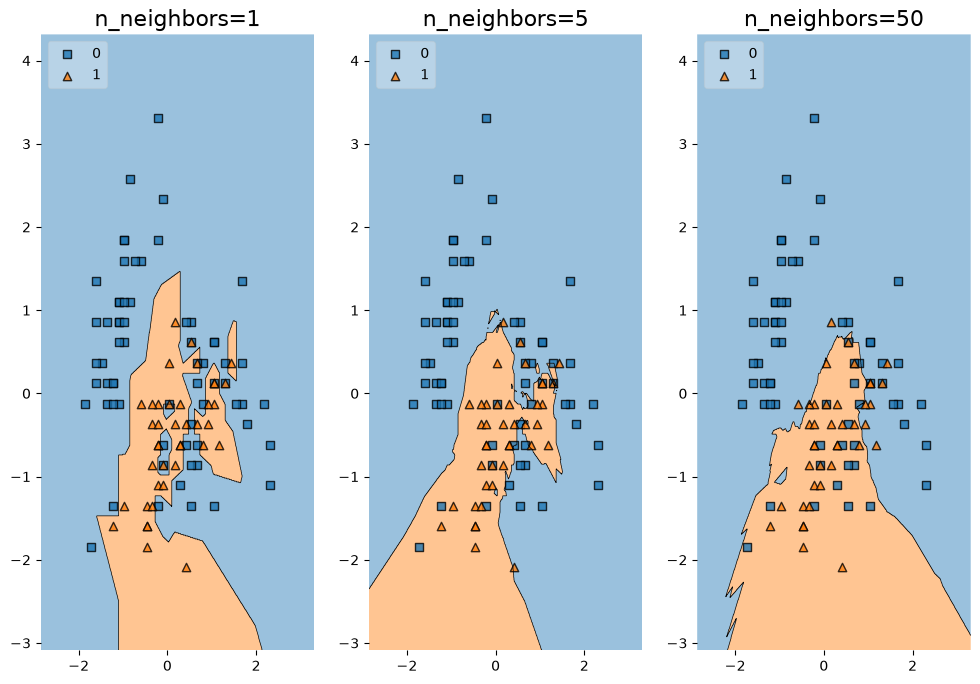

In [24]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 8))
pipes = [knn_1, knn_2, knn_3]

for ind, clf in enumerate(pipes):
    clf.fit(X_train_ss, y_train)
    y_test_pred = clf.predict(X_test_ss)
    score = accuracy_score(y_test, y_test_pred)
    print(f"Правильность при n_neighbors={clf.get_params()['n_neighbors']}: ", score)
    fig = plot_decision_regions(X_train_ss, y_train, clf=clf, legend=2, ax=axes[ind])
    fig.set_title(f"n_neighbors={clf.get_params()['n_neighbors']}", fontsize=16)

#### Дополнительные задания

1. Зачем мы используем `StandardScaler`? 
Что будет, если один из входных признаков умножить на 10^6?

In [25]:
# Здесь должен быть ваш код

# Масштабируем первый признак в миллион раз и сравниваем результаты
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[:, 0] *= 10**6
X_test_scaled[:, 0] *= 10**6

knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train_scaled, y_train)
knn_standardized = KNeighborsClassifier(n_neighbors=5).fit(X_train_ss, y_train)
print('kNN без стандартизации (первый признак × 10^6):',
      accuracy_score(y_test, knn_raw.predict(X_test_scaled)))
print('kNN со стандартизацией:',
      accuracy_score(y_test, knn_standardized.predict(X_test_ss)))

# Проверяем, что StandardScaler устраняет разницу масштабов
scaler_scaled = StandardScaler().fit(X_train_scaled)
X_train_scaled_ss = scaler_scaled.transform(X_train_scaled)
X_test_scaled_ss = scaler_scaled.transform(X_test_scaled)
knn_rescaled = KNeighborsClassifier(n_neighbors=5).fit(X_train_scaled_ss, y_train)
print('kNN после масштабирования и стандартизации:',
      accuracy_score(y_test, knn_rescaled.predict(X_test_scaled_ss)))

kNN без стандартизации (первый признак × 10^6): 0.5555555555555556
kNN со стандартизацией: 0.7555555555555555
kNN после масштабирования и стандартизации: 0.7555555555555555


2. Найдите оптимальное значение для параметра регуляризации $C$ логистической регрессии

In [26]:
# Подбираем C по кросс-валидации только на обучающей выборке
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
search_logreg = GridSearchCV(
    LogisticRegression(max_iter=2000),
    param_grid={'C': np.logspace(-3, 3, 25)},
    scoring='accuracy', cv=cv, n_jobs=-1
)
search_logreg.fit(X_train_ss, y_train)
print('Оптимальное C:', search_logreg.best_params_['C'])
print('Средняя accuracy на кросс-валидации:', search_logreg.best_score_)
print('Accuracy на тестовой выборке:',
      accuracy_score(y_test, search_logreg.predict(X_test_ss)))

Оптимальное C: 0.5623413251903491
Средняя accuracy на кросс-валидации: 0.6285714285714284
Accuracy на тестовой выборке: 0.8444444444444444


3. Найдите оптимальное количество соседей $K$ в методе ближайших соседей

In [27]:
# Подбираем число соседей по кросс-валидации на обучающей выборке
search_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid={'n_neighbors': list(range(1, 51))},
    scoring='accuracy', cv=cv, n_jobs=-1
)
search_knn.fit(X_train_ss, y_train)
print('Оптимальное k:', search_knn.best_params_['n_neighbors'])
print('Средняя accuracy на кросс-валидации:', search_knn.best_score_)
print('Accuracy на тестовой выборке:',
      accuracy_score(y_test, search_knn.predict(X_test_ss)))

Оптимальное k: 6
Средняя accuracy на кросс-валидации: 0.780952380952381
Accuracy на тестовой выборке: 0.7555555555555555


## Нелинейные поверхности

In [28]:
from sklearn.datasets import make_circles

X, y = make_circles(n_samples=200, shuffle=True, noise = 0.1, factor=0.1)

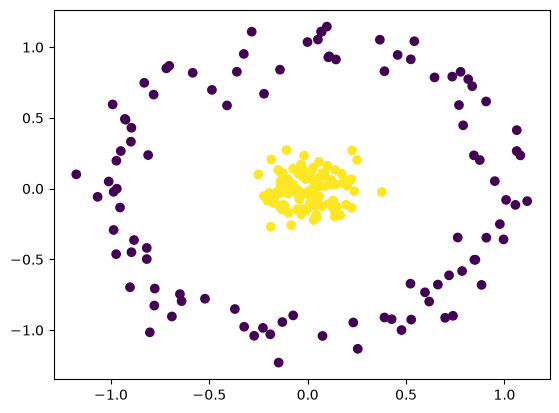

In [29]:
plt.scatter(X[:, 0], X[:, 1], c=y);

In [30]:
# делим данные на обучение и тест
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=123)

In [31]:
# обучаем модель
logreg = LogisticRegression()
logreg.fit(X_train, y_train);

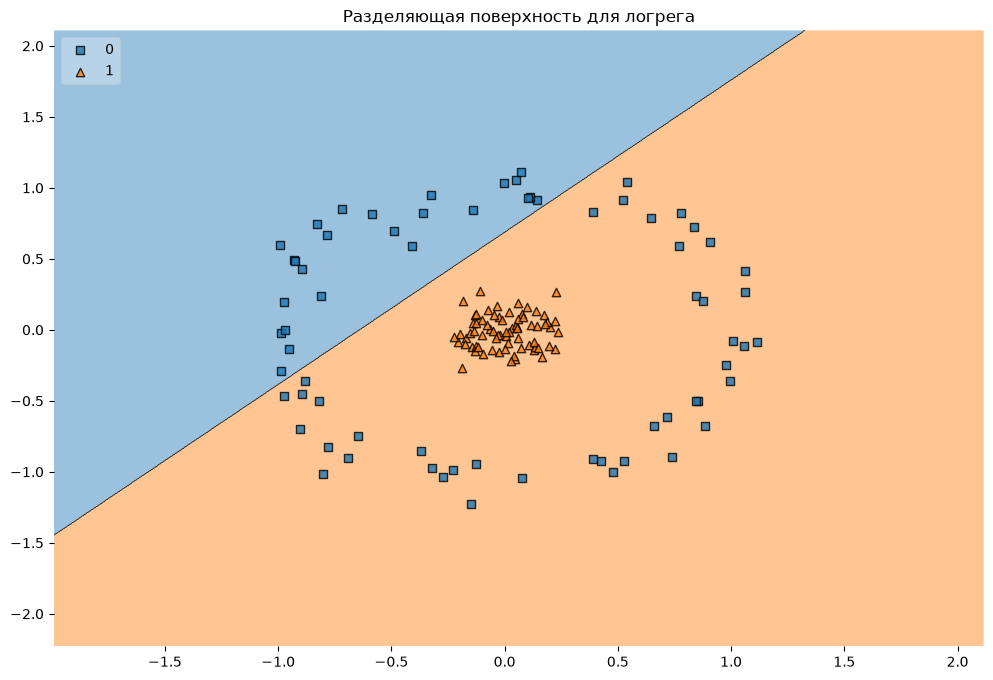

In [32]:
plt.figure(figsize=(12,8))
plot_decision_regions(X_train, y_train, clf=logreg, legend=2)
plt.title('Разделяющая поверхность для логрега');

### Добавим новый признак

$$
X_3 = X_1^{2} + X_2^{2}
$$

In [33]:
X1 = X[:,0]
X2 = X[:,1]
X3 = X1**2+X2**2

X_new = np.c_[X1, X2, X3]

In [34]:
# делим данные на обучение и тест
X_train, X_test, y_train, y_test = train_test_split(X_new, y, test_size=0.3, random_state=123)

#### Логистическая регрессия

In [35]:
# обучаем модель
logreg = LogisticRegression()
logreg.fit(X_train, y_train);

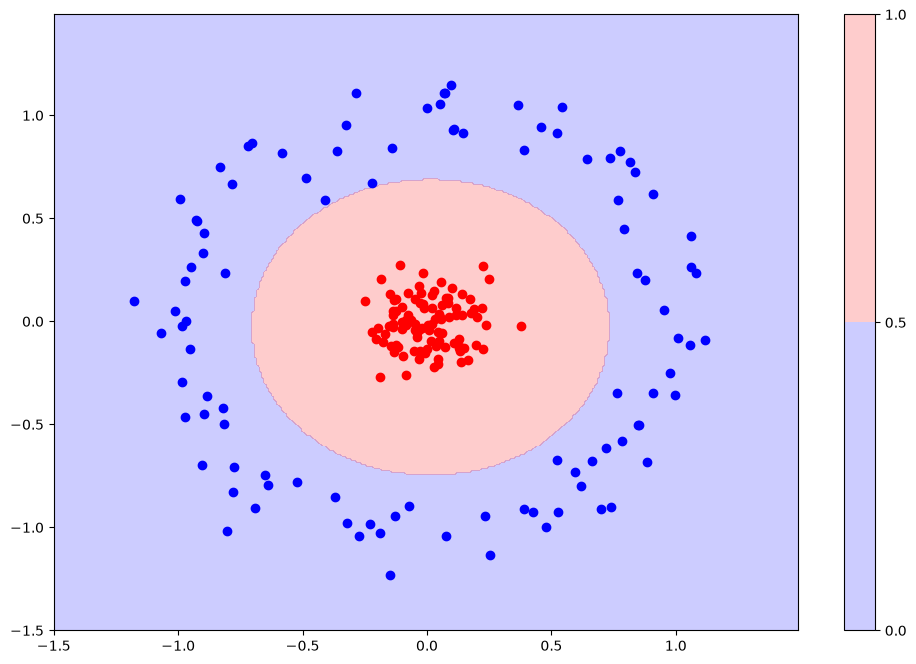

In [36]:
# Plot desicion border

x0, x1 = np.meshgrid(np.arange(-1.5, 1.5, 0.01), np.arange(-1.5, 1.5, 0.01))
xx0, xx1 = x0.ravel(), x1.ravel()
X_grid = np.c_[xx0, xx1, xx0**2 + xx1**2]

y_pred = logreg.predict(X_grid)
y_pred = y_pred.reshape(x0.shape)

plt.figure(figsize=(12,8))
plt.contourf(x0, x1, y_pred, levels=1, cmap=plt.cm.seismic, alpha=0.2)
plt.colorbar()
plt.scatter(X[y==0,0], X[y==0, 1], c='b')
plt.scatter(X[y==1,0], X[y==1, 1], c='r');

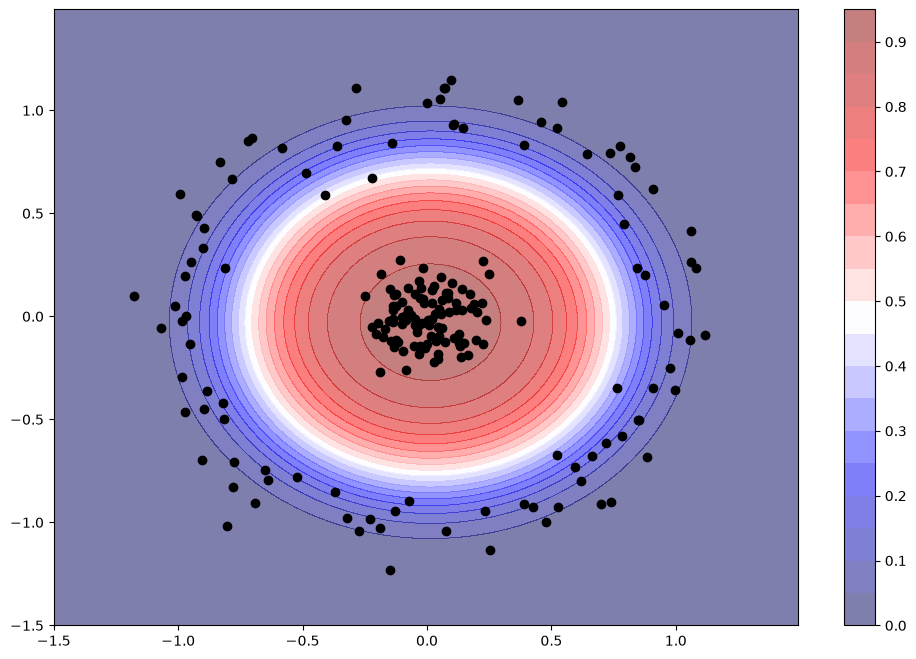

In [37]:
# Plot desicion border

x0, x1 = np.meshgrid(np.arange(-1.5, 1.5, 0.01), np.arange(-1.5, 1.5, 0.01))
xx0, xx1 = x0.ravel(), x1.ravel()
X_grid = np.c_[xx0, xx1, xx0**2 + xx1**2]

y_pred = logreg.predict_proba(X_grid)[:, 1]
y_pred = y_pred.reshape(x0.shape)

plt.figure(figsize=(12,8))
plt.contourf(x0, x1, y_pred, levels=20, cmap=plt.cm.seismic, alpha=0.5)
plt.colorbar()
plt.scatter(X[y==0,0], X[y==0, 1], c='0')
plt.scatter(X[y==1,0], X[y==1, 1], c='0');

#### Метод ближайших соседей

### Задание 6. Реализуйте аналогичные вычисления для метода ближайших соседей

Accuracy kNN на тестовой выборке: 1.0


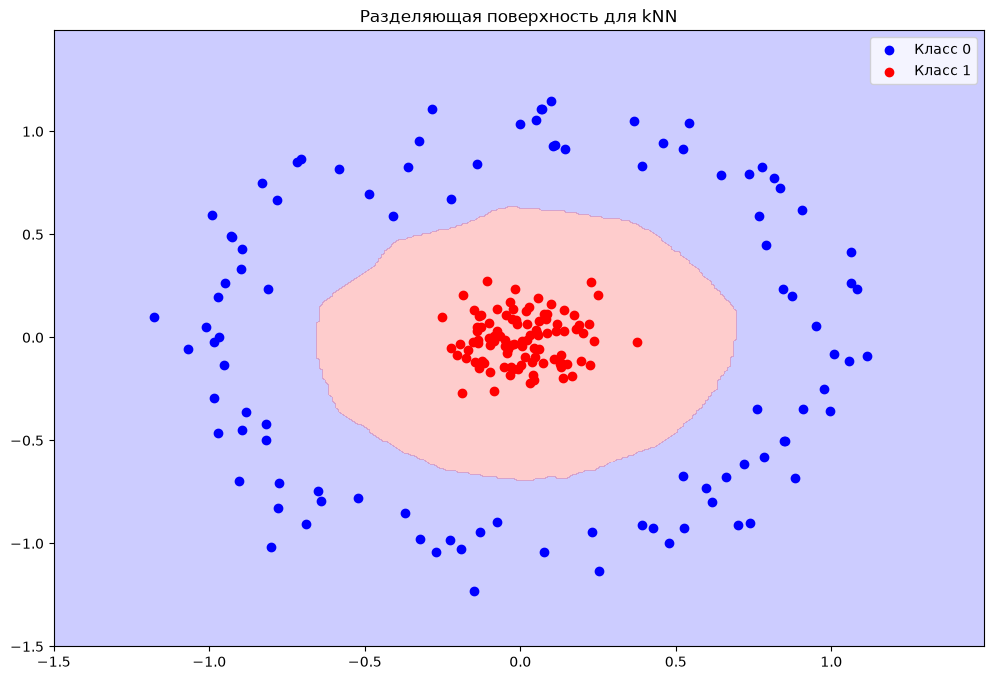

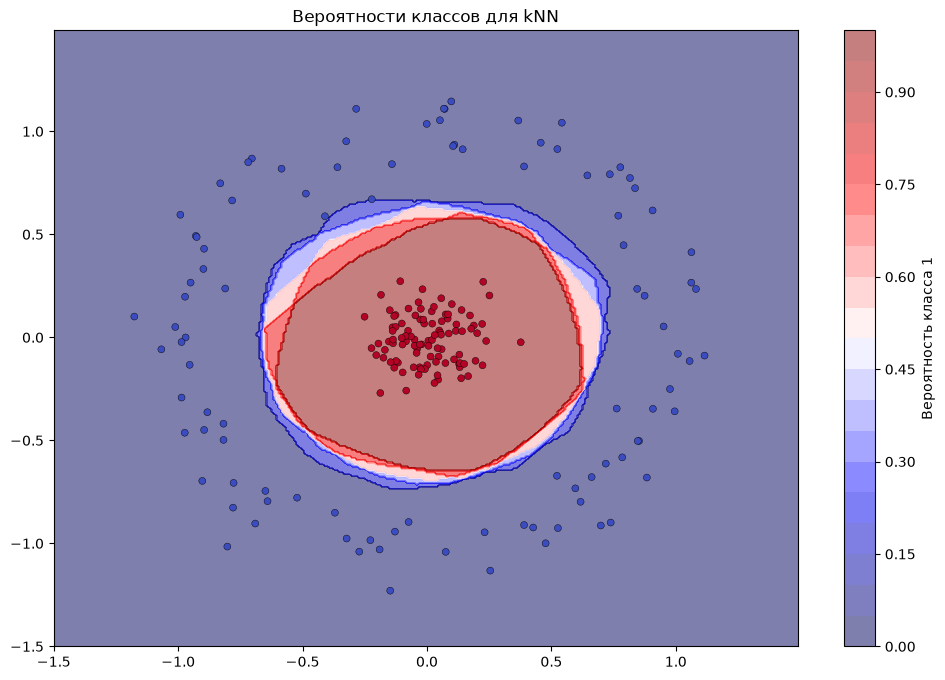

In [40]:
# Здесь должен быть ваш код


# Используем расширенные признаки X1, X2 и X3
knn_circles = KNeighborsClassifier(n_neighbors=5)
knn_circles.fit(X_train, y_train)


pred_knn = knn_circles.predict(X_test)
proba_knn = knn_circles.predict_proba(X_test)[:, 1]
print('Accuracy kNN на тестовой выборке:', accuracy_score(y_test, pred_knn))

x0, x1 = np.meshgrid(np.arange(-1.5, 1.5, 0.01),
                     np.arange(-1.5, 1.5, 0.01))
xx0, xx1 = x0.ravel(), x1.ravel()
X_grid = np.c_[xx0, xx1, xx0**2 + xx1**2]


# Разделяющая поверхность для kNN
class_grid = knn_circles.predict(X_grid).reshape(x0.shape)
plt.figure(figsize=(12, 8))
plt.contourf(x0, x1, class_grid, levels=[-0.5, 0.5, 1.5],
             cmap=plt.cm.seismic, alpha=0.2)
plt.scatter(X[y == 0, 0], X[y == 0, 1], c='b', label='Класс 0')
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='r', label='Класс 1')
plt.title('Разделяющая поверхность для kNN')
plt.legend()
plt.show()

# Карта вероятности класса 1 для kNN
proba_grid = knn_circles.predict_proba(X_grid)[:, 1].reshape(x0.shape)
plt.figure(figsize=(12, 8))
plt.contourf(x0, x1, proba_grid, levels=np.linspace(0, 1, 21),
             cmap=plt.cm.seismic, alpha=0.5)
plt.colorbar(label='Вероятность класса 1')
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm',
            s=25, edgecolors='black', linewidths=0.3)
plt.title('Вероятности классов для kNN')
plt.show()

Accuracy kNN без X3: 1.0


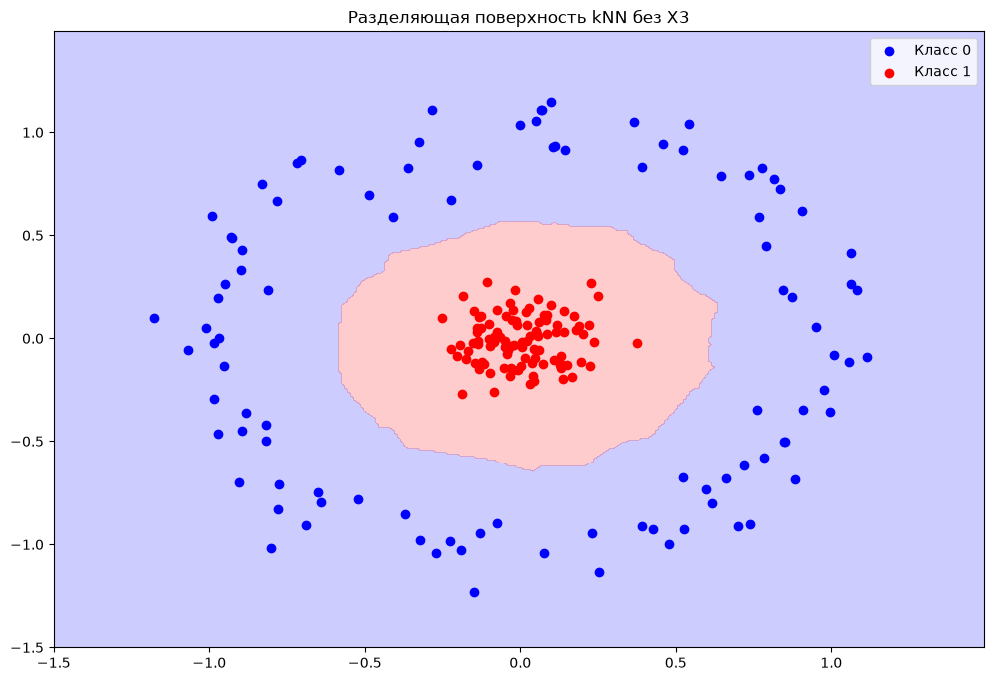

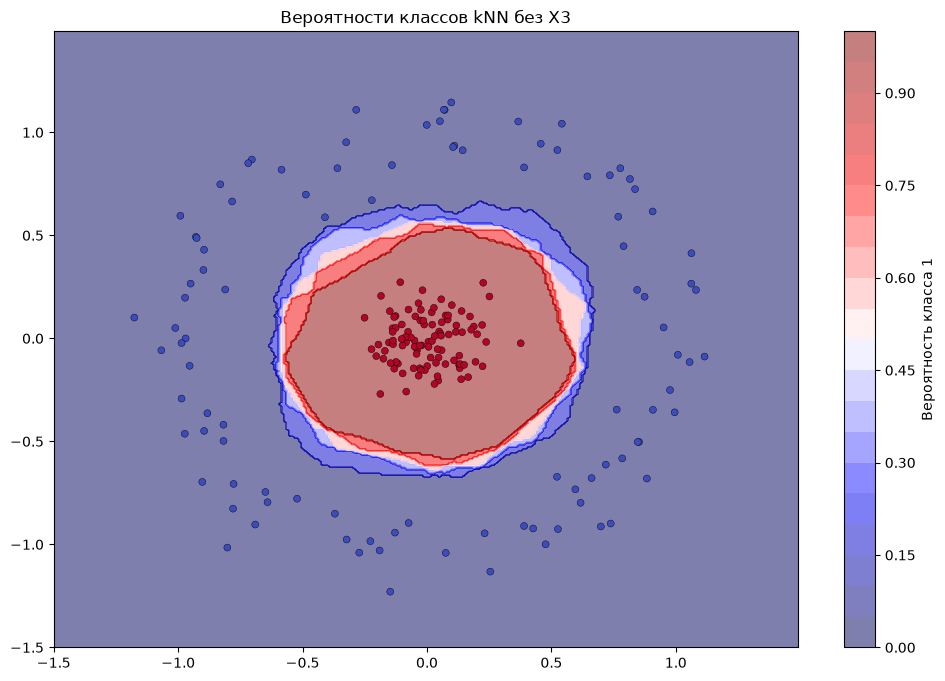

In [ ]:
# kNN без расширенных признаков (только X1 и X2)

knn_circles = KNeighborsClassifier(n_neighbors=5)

knn_circles.fit(X_train[:, :2], y_train)

pred_knn = knn_circles.predict(X_test[:, :2])
proba_knn = knn_circles.predict_proba(X_test[:, :2])[:, 1]

print('Accuracy kNN без X3:', accuracy_score(y_test, pred_knn))

x0, x1 = np.meshgrid(
    np.arange(-1.5, 1.5, 0.01),
    np.arange(-1.5, 1.5, 0.01)
)

xx0, xx1 = x0.ravel(), x1.ravel()

# Только два исходных признака
X_grid = np.c_[xx0, xx1]

# Разделяющая поверхность
class_grid = knn_circles.predict(X_grid).reshape(x0.shape)

plt.figure(figsize=(12, 8))
plt.contourf(
    x0, x1, class_grid,
    levels=[-0.5, 0.5, 1.5],
    cmap=plt.cm.seismic,
    alpha=0.2
)

plt.scatter(X[y == 0, 0], X[y == 0, 1], c='b', label='Класс 0')
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='r', label='Класс 1')
plt.title('Разделяющая поверхность kNN без X3')
plt.legend()
plt.show()

# Карта вероятностей
proba_grid = knn_circles.predict_proba(X_grid)[:, 1].reshape(x0.shape)

plt.figure(figsize=(12, 8))
plt.contourf(
    x0, x1, proba_grid,
    levels=np.linspace(0, 1, 21),
    cmap=plt.cm.seismic,
    alpha=0.5
)
plt.colorbar(label='Вероятность класса 1')
plt.scatter(
    X[:, 0], X[:, 1],
    c=y, cmap='coolwarm',
    s=25, edgecolors='black',
    linewidths=0.3
)
plt.title('Вероятности классов kNN без X3')
plt.show()